# Assignment: PageRank Implementation

## Overview
In this exercise, you will implement the core logic behind **PageRank**, the algorithm that revolutionized web search. Unlike simple graph metrics (like In-Degree), PageRank evaluates the *quality* of links, not just the quantity.

## The Challenge
You are working with a **Scale-Free** graph that mimics the real web. It contains:
1.  **Dead Ends:** Pages with no outgoing links (you must handle these explicitly).
2.  **Sparse Connections:** Real networks are not fully connected.

Your task is to manually build the **Stochastic Transition Matrix** and implement the **Power Iteration** method until the ranks converge.

## The Formula
The rank vector $r$ is updated iteratively using the following equation:

$$r_{t+1} = d \cdot M \cdot r_t + \frac{1-d}{N} \cdot \mathbf{1}$$

Where:
* $M$: The column-stochastic transition matrix (to be implemented).
* $d$: Damping factor (typically $0.85$).
* $N$: Total number of nodes.
* $\mathbf{1}$: A vector of ones (representing random teleportation).

---
**Note:** Do not use `nx.pagerank` for the solution. The goal is to understand the matrix operations from scratch.

Graph ready: 30 nodes. Dead ends at: [5, 12, 25]


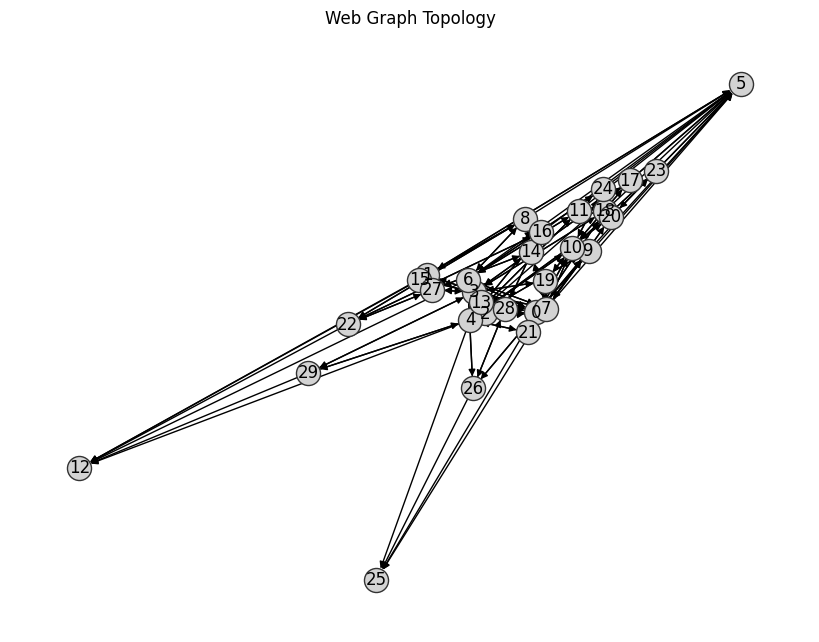

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# 1. Setup Graph (Scale-Free topology)
np.random.seed(42)
N = 30
G = nx.barabasi_albert_graph(N, 3, seed=42)
G = nx.DiGraph(G)

# 2. Inject Dead Ends (remove outgoing links from specific nodes)
dead_ends = [5, 12, 25]
for n in dead_ends:
    G.remove_edges_from(list(G.out_edges(n)))

print(f"Graph ready: {N} nodes. Dead ends at: {dead_ends}")

# 3. Visualize
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G, seed=10)
nx.draw(G, pos, node_size=300, node_color='lightgrey',
        edgecolors='#333', arrowsize=10, with_labels=True)
plt.title("Web Graph Topology")
plt.show()

In [2]:
import numpy as np
import networkx as nx

def build_stochastic_matrix(graph):
    """
    Builds the column-stochastic transition matrix M.
    Handles dead ends by distributing probability uniformly (1/N).
    """
    N = graph.number_of_nodes()
    nodes = sorted(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    
    # Initialize an N x N matrix with zeros
    M = np.zeros((N, N))
    
    for j_node in nodes:
        j = node_to_idx[j_node]
        out_links = list(graph.successors(j_node))
        out_degree = len(out_links)
        
        if out_degree == 0:
            # Handle Dead Ends: Distribute 1/N to all columns
            M[:, j] = 1.0 / N
        else:
            # Distribute 1/out_degree to linked nodes
            for i_node in out_links:
                i = node_to_idx[i_node]
                M[i, j] = 1.0 / out_degree
                
    return M, nodes

In [3]:
def power_iteration(M, d=0.85, max_iter=100, tol=1e-6):
    """
    Implements the Power Iteration algorithm to find the rank vector r.
    """
    N = M.shape[0]
    # Initialize rank vector r_0 with 1/N
    r = np.ones(N) / N
    
    teleport = (1 - d) / N * np.ones(N)
    
    for i in range(max_iter):
        r_next = d * np.dot(M, r) + teleport
        
        # Check for convergence (Euclidean norm)
        if np.linalg.norm(r_next - r) < tol:
            print(f"Converged after {i+1} iterations.")
            return r_next
        
        r = r_next
        
    print("Reached max iterations without full convergence.")
    return r

In [4]:
# 1. Calculate PageRank and In-Degree
M, node_list = build_stochastic_matrix(G)
pagerank_scores = power_iteration(M)

in_degrees = dict(G.in_degree())
total_in_links = sum(in_degrees.values())

# 2. Print Comparison Table
print(f"{'Node':<6} | {'PageRank':<10} | {'In-Degree %':<12}")
print("-" * 35)
for i, node in enumerate(node_list):
    deg_percent = (in_degrees[node] / total_in_links) * 100 if total_in_links > 0 else 0
    print(f"{node:<6} | {pagerank_scores[i]:.6f} | {deg_percent:.2f}%")

Converged after 18 iterations.
Node   | PageRank   | In-Degree % 
-----------------------------------
0      | 0.063361 | 7.30%
1      | 0.018769 | 1.46%
2      | 0.022492 | 2.19%
3      | 0.057078 | 5.84%
4      | 0.064201 | 7.30%
5      | 0.083160 | 10.95%
6      | 0.059617 | 6.57%
7      | 0.057521 | 6.57%
8      | 0.029892 | 2.92%
9      | 0.023322 | 2.19%
10     | 0.046637 | 5.11%
11     | 0.018003 | 1.46%
12     | 0.037229 | 4.38%
13     | 0.024358 | 2.19%
14     | 0.044050 | 4.38%
15     | 0.013644 | 0.73%
16     | 0.032525 | 2.92%
17     | 0.021103 | 1.46%
18     | 0.019752 | 1.46%
19     | 0.025371 | 2.19%
20     | 0.023465 | 2.19%
21     | 0.022330 | 2.19%
22     | 0.027562 | 2.19%
23     | 0.019848 | 1.46%
24     | 0.019469 | 1.46%
25     | 0.027811 | 2.92%
26     | 0.025793 | 2.19%
27     | 0.027361 | 2.19%
28     | 0.024816 | 2.19%
29     | 0.019461 | 1.46%


## Numerical checks

These checks verify that the transition matrix is column-stochastic and that the final PageRank scores form a probability distribution.

In [5]:
column_sums = M.sum(axis=0)
assert np.allclose(column_sums, 1.0), "Every transition-matrix column should sum to 1."
assert np.isclose(pagerank_scores.sum(), 1.0, atol=1e-5), "PageRank scores should sum to 1."
print(f"Transition matrix column sums: min={column_sums.min():.6f}, max={column_sums.max():.6f}")
print(f"Sum of PageRank scores: {pagerank_scores.sum():.6f}")

Transition matrix column sums: min=1.000000, max=1.000000
Sum of PageRank scores: 1.000000


## Q1 — Why must the transition matrix be column-stochastic?

The rank vector is a probability distribution over pages, so its total probability mass should remain 1. With the column-vector convention used here, each column of the transition matrix represents where a surfer goes from one page, and each column must sum to 1. If a dangling node (a page with no outgoing links) were left as an all-zero column, probability mass would leak away on each iteration. This implementation handles dangling nodes by distributing their probability uniformly across all nodes, preserving the column sums.

## Q2 — Effect of the damping factor

**A. When the damping factor is close to 1:** the random surfer follows links almost all the time and teleports less often. The ranking is more dependent on the graph structure, and power iteration typically converges more slowly as the damping factor approaches 1. Teleportation helps the Markov chain move between graph regions and improves convergence.

**B. When the damping factor is 0:** the link-following term disappears. Every update becomes `r_next = 1/N`, so all pages receive the same uniform score, regardless of the graph.

Q3

Node 16 has an In-Degree of only 2.92%. However, its PageRank is 0.032525. If we compare it to Node 25, which has the exact same In-Degree (2.92%), we see that Node 25 has a much lower PageRank (0.027811). This indicates that the pages linking to Node 16 are much more "important" or authoritative than those linking to Node 25.

Node 16 represents a high-quality resource that is cited by experts (authorities), whereas nodes like Node 25 represent pages that have the same number of citations, but from less relevant or lower-quality sources.

## Q4 — Teleportation and isolated pages

**A.** The teleportation contribution to each page at each iteration is `(1 - d) / N`.

**B.** Yes, teleportation helps a page receive rank even when no other page links to it. However, its final PageRank is not necessarily exactly `(1 - d) / N`: contributions from other transition columns, including the redistribution used for dangling nodes, can add more probability mass.